# SIS-1: Climate and Population Growth of Kazakhstan Cities

**Course:** Data Collection & Preparation (KBTU, Fall 2026)  
**Student:** Nurzhan Kalmurat, ID 24B031138 (individual work, team name: `Kalmurat`)

## Project idea
Kazakhstan is a very big country. The south is warm and the north is very cold in winter. In the same time some cities grow very fast and some cities lose people. In this project I collect real data from two different sources and check how climate is different between cities and if climate is connected with population growth.

**Research questions**
1. How does the climate change from the south to the north of Kazakhstan?
2. Which cities have the most extreme climate (cold winter, hot summer, big difference between seasons)?
3. Is there a link between the climate of a city and its population growth from 1999 to 2023?

## Data sources
| # | Source | Type | What I take |
|---|---|---|---|
| 1 | [Wikipedia: List of cities in Kazakhstan](https://en.wikipedia.org/wiki/List_of_cities_in_Kazakhstan) | Static web page (scraping with `requests` + `BeautifulSoup`) | city name, year of foundation, population 1979-2023, status, province |
| 2 | [Open-Meteo Geocoding API](https://open-meteo.com/en/docs/geocoding-api) | REST API, JSON, no key | latitude, longitude, elevation of each city |
| 3 | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) | REST API, JSON, no key | daily weather for the full year 2025 |

## Pipeline
`Collect (scraping + API)` -> `Clean` -> `Merge (by city)` -> `Analyze (statistics, correlation)` -> `Visualize` -> `Conclusions`

## 0. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')

# folders for raw data, clean data and figures
RAW = Path('data/raw')
CLEAN = Path('data/processed')
FIG = Path('figures')
for folder in (RAW, CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)

# I introduce myself to the servers (good practice from the lecture)
HEADERS = {'User-Agent': 'KBTU-DCP-SIS1/1.0 (student project, educational use)'}

WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_cities_in_Kazakhstan'
GEO_URL = 'https://geocoding-api.open-meteo.com/v1/search'
WEATHER_URL = 'https://archive-api.open-meteo.com/v1/archive'
START_DATE, END_DATE = '2025-01-01', '2025-12-31'

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.3.3 | numpy 2.3.5


## 1. Data collection, part A: web scraping (Wikipedia)

### 1.1 Check robots.txt
Before scraping I check that the page is allowed for bots. I download `robots.txt` with `requests` (with my User-Agent) and give it to `RobotFileParser`.

In [2]:
from urllib import robotparser

robots = requests.get('https://en.wikipedia.org/robots.txt', headers=HEADERS, timeout=20)
print('robots.txt status:', robots.status_code)

rp = robotparser.RobotFileParser()
rp.parse(robots.text.splitlines())
allowed = rp.can_fetch(HEADERS['User-Agent'], WIKI_URL)
print('Scraping of the page is allowed:', allowed)
assert allowed, 'robots.txt does not allow this page'

robots.txt status: 200
Scraping of the page is allowed: True


### 1.2 Download the HTML page
The page is **static**: the table is already inside the HTML (I checked with "View Page Source"), so `requests` + `BeautifulSoup` is enough, no Selenium.

In [3]:
response = requests.get(WIKI_URL, headers=HEADERS, timeout=30)
print('Status code:', response.status_code, '| URL:', response.url)
response.raise_for_status()

html = response.text
(RAW / 'wikipedia_cities_kz.html').write_text(html, encoding='utf-8')  # keep a raw copy
print('HTML length:', len(html), 'characters')

Status code: 200 | URL: https://en.wikipedia.org/wiki/List_of_cities_in_Kazakhstan
HTML length: 275040 characters


### 1.3 Parse the table with BeautifulSoup
The data is in `<table class="wikitable">`. I take the header row (`<th>`), then go row by row (`<tr>`) and read every cell (`<td>`). Footnote marks like `[1]` are inside `<sup>` tags, so I remove them first.

In [4]:
soup = BeautifulSoup(html, 'html.parser')
table = soup.select_one('table.wikitable')
print('Tables with class "wikitable" on the page:', len(soup.select('table.wikitable')))

for sup in table.find_all('sup'):  # remove footnotes [1], [2]...
    sup.decompose()

rows = table.find_all('tr')
header = [th.get_text(' ', strip=True) for th in rows[0].find_all('th')]
print('Columns:', header)

records = []
for tr in rows[1:]:
    cells = tr.find_all(['td', 'th'])
    if len(cells) != len(header):  # skip broken / empty rows
        continue
    values = [c.get_text(' ', strip=True) for c in cells]
    records.append(dict(zip(header, values)))

wiki_raw = pd.DataFrame(records)
wiki_raw.to_csv(RAW / 'wiki_cities_raw.csv', index=False, encoding='utf-8-sig')
print('Scraped rows:', wiki_raw.shape)
wiki_raw.head()

Tables with class "wikitable" on the page: 1
Columns: ['Insignia', 'Name in English', 'Name in Kazakh', 'Previous name(s)', 'City since', 'Pop. 1979', 'Pop. 1989', 'Pop. 1999', 'Pop. 2008', 'Pop. 2023', 'Status', 'Province']
Scraped rows: (32, 12)


,Insignia,Name in English,Name in Kazakh,Previous name(s),City since,Pop. 1979,Pop. 1989,Pop. 1999,Pop. 2008,Pop. 2023,Status,Province
0,,Almaty,Алматы Almaty [ ɑɫmɑˈtə ],"Vernyy, Alma-Ata",1867,"909,644","1,127,884","1,129,356","1,328,362","2,217,700",1,Capital 1929–1997
1,,Astana,Астана Astana [ ɑstɑˈnɑ ],"Akmola, Akmolinsk, Tselinograd, Nur-Sultan",1831,"233,638","277,365","312,965","389,189","1,417,214",1,Capital
2,,Shymkent,Шымкент Şymkent [ ʃəmˈkʲent ],"Chimkent, Chernyayev",Middle Ages,"321,535","380,091","390,200","454,583","1,216,000",1,Shymkent
3,,Aktobe,Ақтөбе Aqtöbe [ ɑqtɵˈbʲe ],Aktyubinsk,1880,"190,569","253,532","253,088","285,507","560,820",2,Aktobe Province
4,,Karaganda,Қарағанды Qarağandy [ qɑˌrɑʁɑnˈdə ],,1934,"571,877","507,318","436,864","451,800","515,819",2,Karagandy Province


In [5]:
wiki_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Insignia          32 non-null     object
 1   Name in English   32 non-null     object
 2   Name in Kazakh    32 non-null     object
 3   Previous name(s)  32 non-null     object
 4   City since        32 non-null     object
 5   Pop. 1979         32 non-null     object
 6   Pop. 1989         32 non-null     object
 7   Pop. 1999         32 non-null     object
 8   Pop. 2008         32 non-null     object
 9   Pop. 2023         32 non-null     object
 10  Status            32 non-null     object
 11  Province          32 non-null     object
dtypes: object(12)
memory usage: 3.1+ KB


**What I see in the raw data (problems to fix):**
- all columns are text (`object`), numbers have commas: `"2,217,700"`;
- `City since` has text values like `"Middle Ages"` and `"ancient"`;
- some populations are empty (city did not exist in 1979);
- `Province` is written in different ways: `"Province"`, `"province"`, `"Region"`, and old names (`"South Kazakhstan"`), for Almaty and Astana it says `"Capital"`;
- columns `Insignia` and `Name in Kazakh` are not needed for the analysis.

## 2. Cleaning the scraped data

In [6]:
wiki = wiki_raw.copy()

# 1) drop columns I do not need
wiki = wiki.drop(columns=['Insignia', 'Name in Kazakh'])

# 2) rename columns to simple snake_case names
wiki = wiki.rename(columns={
    'Name in English': 'city', 'Previous name(s)': 'previous_names', 'City since': 'city_since',
    'Pop. 1979': 'pop_1979', 'Pop. 1989': 'pop_1989', 'Pop. 1999': 'pop_1999',
    'Pop. 2008': 'pop_2008', 'Pop. 2023': 'pop_2023', 'Status': 'status', 'Province': 'province'})

# 3) strip spaces, empty strings -> NaN, drop empty rows
wiki = wiki.apply(lambda col: col.str.strip())
wiki = wiki.replace('', np.nan).dropna(subset=['city'])

# 4) numbers: remove commas and convert to integer (Int64 keeps NaN)
pop_cols = ['pop_1979', 'pop_1989', 'pop_1999', 'pop_2008', 'pop_2023']
for col in pop_cols:
    wiki[col] = pd.to_numeric(wiki[col].str.replace(',', '', regex=False), errors='coerce').astype('Int64')
wiki['status'] = pd.to_numeric(wiki['status'], errors='coerce').astype('Int64')

# 5) city_since: keep only the year, text like "ancient" becomes NaN
wiki['city_since'] = pd.to_numeric(wiki['city_since'].str.extract(r'(\d{3,4})')[0], errors='coerce').astype('Int64')

wiki[['city', 'city_since', 'pop_1999', 'pop_2023', 'status', 'province']].head(8)

,city,city_since,pop_1999,pop_2023,status,province
0,Almaty,1867,1129356,2217700,1,Capital 1929–1997
1,Astana,1831,312965,1417214,1,Capital
2,Shymkent,<NA>,390200,1216000,1,Shymkent
3,Aktobe,1880,253088,560820,2,Aktobe Province
4,Karaganda,1934,436864,515819,2,Karagandy Province
5,Taraz,<NA>,330125,427394,2,Jambyl Province
6,Oskemen,1868,310950,400142,2,East Kazakhstan Region
7,Pavlodar,1861,320400,367254,2,Pavlodar Province


### 2.1 Make the province names the same
I remove the words "Province" / "Region", use the new name for South Kazakhstan (it is **Turkistan Region** since 2018) and for the capitals I write `"<city> City"`. Then I add a bigger group `macro_region` (South, North, Central, East, West) to compare parts of the country.

In [7]:
print('Before:', sorted(wiki['province'].unique()), '\n')

prov = wiki['province'].str.replace(r'\s+(province|region)$', '', case=False, regex=True)
prov = prov.replace({'South Kazakhstan': 'Turkistan', 'Shymkent': 'Shymkent City'})
is_capital = prov.str.startswith('Capital')
wiki['province'] = np.where(is_capital, wiki['city'] + ' City', prov)

MACRO_REGION = {
    'Almaty City': 'South', 'Almaty': 'South', 'Shymkent City': 'South', 'Turkistan': 'South',
    'Jambyl': 'South', 'Kyzylorda': 'South',
    'Astana City': 'North', 'Akmola': 'North', 'Kostanay': 'North', 'North Kazakhstan': 'North', 'Pavlodar': 'North',
    'Karagandy': 'Central',
    'East Kazakhstan': 'East',
    'Aktobe': 'West', 'Atyrau': 'West', 'Mangystau': 'West', 'West Kazakhstan': 'West'}
wiki['macro_region'] = wiki['province'].map(MACRO_REGION)

print('After:', sorted(wiki['province'].unique()))
print('Provinces without macro region:', wiki.loc[wiki['macro_region'].isna(), 'province'].tolist())

Before: ['Akmola Province', 'Aktobe Province', 'Almaty Province', 'Atyrau province', 'Capital', 'Capital 1929–1997', 'East Kazakhstan Region', 'Jambyl Province', 'Karagandy Province', 'Karagandy Region', 'Kostanay Province', 'Kyzylorda Province', 'Mangystau Province', 'North Kazakhstan Province', 'Pavlodar Province', 'Pavlodar Region', 'Shymkent', 'South Kazakhstan Province', 'West Kazakhstan Region'] 

After: ['Akmola', 'Aktobe', 'Almaty', 'Almaty City', 'Astana City', 'Atyrau', 'East Kazakhstan', 'Jambyl', 'Karagandy', 'Kostanay', 'Kyzylorda', 'Mangystau', 'North Kazakhstan', 'Pavlodar', 'Shymkent City', 'Turkistan', 'West Kazakhstan']
Provinces without macro region: []


### 2.2 Check duplicates and missing values

In [8]:
print('Duplicate cities:', wiki.duplicated('city').sum())
print('\nMissing values per column:')
print(wiki.isna().sum())

Duplicate cities: 0

Missing values per column:
city               0
previous_names    14
city_since         3
pop_1979           3
pop_1989           0
pop_1999           0
pop_2008           0
pop_2023           0
status             0
province           0
macro_region       0
dtype: int64


In [9]:
wiki[wiki[['pop_1979', 'city_since']].isna().any(axis=1)][['city', 'city_since', 'pop_1979', 'pop_1989', 'pop_2023']]

,city,city_since,pop_1979,pop_1989,pop_2023
2,Shymkent,<NA>,321535,380091,1216000
5,Taraz,<NA>,263793,303961,427394
11,Aktau,1963,<NA>,159245,270886
15,Turkistan,<NA>,66741,77692,220133
23,Baikonur,1969,<NA>,74700,76019
28,Schuchinsk,1939,<NA>,55500,47625


**Decision about missing values:**
- `pop_1979` is empty for 3 cities (Aktau, Baikonur, Schuchinsk): there was no census number for them, so I do **not** fill it with a fake number. I use the period **1999 -> 2023** for growth, and these years have no missing values.
- `city_since` is empty when Wikipedia writes "ancient" or "Middle Ages" (Shymkent, Taraz, Turkistan). These are very old cities, I keep NaN because I do not know the exact year.
- `previous_names` is empty for 14 cities because they never had another name. This is not an error, I keep it only as information.

### 2.3 New columns (feature engineering)
- `growth_pct` = population change 1999 -> 2023 in %
- `cagr_pct` = average growth per year (compound annual growth rate)

In [10]:
wiki['growth_pct'] = ((wiki['pop_2023'] - wiki['pop_1999']) / wiki['pop_1999'] * 100).astype(float).round(1)
wiki['cagr_pct'] = (((wiki['pop_2023'] / wiki['pop_1999']).astype(float) ** (1 / 24) - 1) * 100).round(2)

wiki.to_csv(CLEAN / 'wiki_cities_clean.csv', index=False, encoding='utf-8-sig')
wiki.dtypes

city               object
previous_names     object
city_since          Int64
pop_1979            Int64
pop_1989            Int64
pop_1999            Int64
pop_2008            Int64
pop_2023            Int64
status              Int64
province           object
macro_region       object
growth_pct        float64
cagr_pct          float64
dtype: object

## 3. Data collection, part B: Open-Meteo API

Open-Meteo is a free REST API: no key, answer in JSON. I use **GET** requests with **query parameters** (`params=`).

I write one helper function for all requests:
- `timeout` so the program does not wait forever;
- check of the **status code**;
- **retry with backoff** only for 429 / 5xx errors and network errors (from the lecture: do not retry 400/404, fix the request);
- small pause between requests to respect the rate limit.

In [11]:
def get_json(url, params, retries=3, pause=1.0):
    """GET request -> Python dict. Returns None if all attempts fail."""
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=30)
            if r.status_code in (429, 500, 502, 503, 504):
                wait = pause * 2 ** attempt
                print(f'   status {r.status_code}, wait {wait:.0f}s and retry')
                time.sleep(wait)
                continue
            r.raise_for_status()  # 4xx -> error, no retry
            return r.json()
        except requests.exceptions.HTTPError as e:
            print('   client error, no retry:', e)
            return None
        except requests.exceptions.RequestException as e:
            print(f'   attempt {attempt} failed: {e}')
            time.sleep(pause * 2 ** attempt)
    return None

### 3.1 Geocoding: coordinates of every city
The Geocoding API returns many places with the same name (for example "Aktau" is also a village in Karaganda region). So I keep only results in Kazakhstan (`country_code == "KZ"`), only populated places (`feature_code` starts with `PPL`) and take the one with the biggest population. Some cities have another official spelling in the database, for them I use an alias.

In [12]:
ALIASES = {'Oskemen': 'Ust-Kamenogorsk', 'Janaözen': 'Zhanaozen',
           'Jezkazgan': 'Zhezkazgan', 'Schuchinsk': 'Shchuchinsk'}

def geocode(city):
    for name in [city, ALIASES.get(city)]:
        if name is None:
            continue
        data = get_json(GEO_URL, {'name': name, 'count': 20, 'language': 'en', 'format': 'json'})
        results = (data or {}).get('results', [])
        places = [p for p in results
                  if p.get('country_code') == 'KZ' and p.get('feature_code', '').startswith('PPL')]
        if places:
            best = max(places, key=lambda p: p.get('population') or 0)
            return {'city': city, 'geo_name': best['name'], 'admin1': best.get('admin1'),
                    'latitude': best['latitude'], 'longitude': best['longitude'],
                    'elevation': best.get('elevation')}
    return {'city': city}

geo_rows = []
for city in wiki['city']:
    geo_rows.append(geocode(city))
    time.sleep(0.2)

geo = pd.DataFrame(geo_rows)
geo.to_csv(RAW / 'geocoding_raw.csv', index=False, encoding='utf-8-sig')
print('Cities without coordinates:', geo['latitude'].isna().sum())
geo.head(10)

Cities without coordinates: 0


,city,geo_name,admin1,latitude,longitude,elevation
0,Almaty,Almaty,Almaty,43.25249,76.91150,783.0
1,Astana,Astana,Astana,51.18010,71.44598,358.0
2,Shymkent,Shymkent,Shymkent,42.30988,69.60042,520.0
3,Aktobe,Aktobe,Aktobe,50.27969,57.20718,210.0
4,Karaganda,Karaganda,Karaganda,49.80187,73.10211,545.0
5,Taraz,Taraz,Zhambyl,42.89799,71.37334,611.0
6,Oskemen,Ust-Kamenogorsk,East Kazakhstan,49.97143,82.60586,287.0
7,Pavlodar,Pavlodar,Pavlodar Region,52.27601,76.96881,125.0
8,Semey,Semey,Abai Region,50.42064,80.25025,195.0
9,Kyzylorda,Kyzylorda,Kyzylorda,44.85278,65.50917,128.0


### 3.2 Daily weather for 2025 (Historical Weather API)
For every city I send one request with its coordinates. I ask for 7 daily variables. The JSON answer has a `daily` object with lists, it is easy to turn into a DataFrame. Many requests in a loop -> I put them together with `pd.concat`.

In [13]:
DAILY_VARS = ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
              'precipitation_sum', 'snowfall_sum', 'wind_speed_10m_max', 'sunshine_duration']

frames = []
for _, row in geo.dropna(subset=['latitude']).iterrows():
    params = {'latitude': row['latitude'], 'longitude': row['longitude'],
              'start_date': START_DATE, 'end_date': END_DATE,
              'daily': ','.join(DAILY_VARS), 'timezone': 'auto'}
    data = get_json(WEATHER_URL, params)
    if data is None:
        print('No data for', row['city'])
        continue
    df_city = pd.DataFrame(data['daily'])
    df_city.insert(0, 'city', row['city'])
    frames.append(df_city)
    time.sleep(0.5)  # be polite to the server

weather_raw = pd.concat(frames, ignore_index=True)
weather_raw.to_csv(RAW / 'weather_daily_2025_raw.csv', index=False, encoding='utf-8-sig')
print('Downloaded:', weather_raw.shape, '| cities:', weather_raw['city'].nunique())
print('Units from the API:', data['daily_units'])
weather_raw.head()

Downloaded: (11680, 9) | cities: 32
Units from the API: {'time': 'iso8601', 'temperature_2m_mean': '°C', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'snowfall_sum': 'cm', 'wind_speed_10m_max': 'km/h', 'sunshine_duration': 's'}


,city,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,snowfall_sum,wind_speed_10m_max,sunshine_duration
0,Almaty,2025-01-01,-2.4,-0.9,-4.7,0.0,0.00,5.9,20852.86
1,Almaty,2025-01-02,-2.1,-0.4,-5.1,0.0,0.00,6.1,17303.83
2,Almaty,2025-01-03,-3.8,-2.4,-6.6,0.0,0.00,10.0,29034.88
3,Almaty,2025-01-04,-3.5,1.0,-6.8,0.0,0.00,24.7,29043.15
4,Almaty,2025-01-05,-3.9,-1.9,-6.3,0.2,0.14,21.0,15266.14


Example of the JSON structure of one answer (only the first 3 days):

In [14]:
{k: (v[:3] if isinstance(v, list) else v) for k, v in data['daily'].items()}

{'time': ['2025-01-01', '2025-01-02', '2025-01-03'],
 'temperature_2m_mean': [-12.2, -8.5, -3.2],
 'temperature_2m_max': [-5.4, -4.3, -0.5],
 'temperature_2m_min': [-17.5, -12.2, -9.9],
 'precipitation_sum': [5.3, 2.2, 2.1],
 'snowfall_sum': [3.71, 1.54, 0.91],
 'wind_speed_10m_max': [36.2, 34.7, 43.5],
 'sunshine_duration': [3437.81, 0.0, 0.0]}

## 4. Cleaning the weather data

In [15]:
weather = weather_raw.rename(columns={
    'time': 'date', 'temperature_2m_mean': 'temp_mean', 'temperature_2m_max': 'temp_max',
    'temperature_2m_min': 'temp_min', 'precipitation_sum': 'precip_mm', 'snowfall_sum': 'snow_cm',
    'wind_speed_10m_max': 'wind_max_kmh', 'sunshine_duration': 'sunshine_s'})

# data types: text date -> datetime, seconds of sun -> hours
weather['date'] = pd.to_datetime(weather['date'])
weather['sunshine_h'] = (weather['sunshine_s'] / 3600).round(2)
weather = weather.drop(columns='sunshine_s')
weather['month'] = weather['date'].dt.month

print('Duplicates (city + date):', weather.duplicated(['city', 'date']).sum())
print('Days per city:', weather.groupby('city').size().unique())
print('\nMissing values:')
print(weather.isna().sum())

Duplicates (city + date): 0
Days per city: [365]

Missing values:
city            0
date            0
temp_mean       0
temp_max        0
temp_min        0
precip_mm       0
snow_cm         0
wind_max_kmh    0
sunshine_h      0
month           0
dtype: int64


In [16]:
# missing values: fill short gaps inside each city with linear interpolation
num_cols = ['temp_mean', 'temp_max', 'temp_min', 'precip_mm', 'snow_cm', 'wind_max_kmh', 'sunshine_h']
missing_before = int(weather[num_cols].isna().sum().sum())
weather = weather.drop_duplicates(['city', 'date']).sort_values(['city', 'date'])
weather[num_cols] = weather.groupby('city')[num_cols].transform(lambda s: s.interpolate(limit=3, limit_direction='both'))
print(f'Missing values before: {missing_before}, after: {int(weather[num_cols].isna().sum().sum())}')

# logic checks (data quality)
bad_order = (weather['temp_min'] > weather['temp_mean']) | (weather['temp_mean'] > weather['temp_max'])
print('Rows where min <= mean <= max is broken:', int(bad_order.sum()))
print('Negative precipitation:', int((weather['precip_mm'] < 0).sum()))

Missing values before: 0, after: 0
Rows where min <= mean <= max is broken: 0
Negative precipitation: 0


### 4.1 Outliers (IQR method)
I count values outside `Q1 - 1.5*IQR ... Q3 + 1.5*IQR` for every variable.

In [17]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outliers = pd.Series({col: iqr_outliers(weather[col]) for col in num_cols}, name='outliers (IQR)')
outliers.to_frame().T

,temp_mean,temp_max,temp_min,precip_mm,snow_cm,wind_max_kmh,sunshine_h
outliers (IQR),0,0,6,1981,1613,161,0


In [18]:
weather.nlargest(3, 'precip_mm')[['city', 'date', 'precip_mm']]

,city,date,precip_mm
10097,Ridder,2025-08-31,64.7
10048,Ridder,2025-07-13,47.8
10069,Ridder,2025-08-03,44.8


**Decision:** most "outliers" are in `precip_mm` and `snow_cm`. This is normal: most days have 0 mm, so any rainy or snowy day looks like an outlier. Strong wind days are also rare, so they are outside the IQR range. Temperature has almost no outliers. The data passed the logic checks above, so these are **real weather events, not errors**, and I keep them (if I delete them, the climate looks softer than it is and the year sums of rain and snow become wrong).

### 4.2 Climate summary for every city (groupby + agg)

In [19]:
climate = weather.groupby('city').agg(
    temp_year=('temp_mean', 'mean'),
    temp_max_abs=('temp_max', 'max'),
    temp_min_abs=('temp_min', 'min'),
    precip_year_mm=('precip_mm', 'sum'),
    snow_year_cm=('snow_cm', 'sum'),
    wind_max_avg=('wind_max_kmh', 'mean'),
    sunshine_year_h=('sunshine_h', 'sum'),
    frost_days=('temp_min', lambda s: int((s < 0).sum())),
    hot_days=('temp_max', lambda s: int((s > 30).sum())),
)
# average temperature of January and July
monthly_city = weather.pivot_table(index='city', columns='month', values='temp_mean', aggfunc='mean')
climate['temp_jan'] = monthly_city[1]
climate['temp_jul'] = monthly_city[7]
climate['temp_range'] = climate['temp_jul'] - climate['temp_jan']  # how continental the climate is
climate = climate.round(1).reset_index()
climate.head()

,city,temp_year,temp_max_abs,temp_min_abs,precip_year_mm,snow_year_cm,wind_max_avg,sunshine_year_h,frost_days,hot_days,temp_jan,temp_jul,temp_range
0,Aktau,14.1,39.4,-11.9,281.7,43.5,23.7,3209.1,65,62,2.7,28.3,25.6
1,Aktobe,8.0,34.9,-28.9,356.4,70.8,17.5,2978.3,140,26,-6.9,22.7,29.6
2,Almaty,11.5,38.7,-19.9,345.8,63.0,9.5,3421.2,129,75,-4.8,27.8,32.6
3,Arkalyk,6.8,36.0,-30.8,369.8,80.4,22.4,3067.4,159,19,-10.0,21.5,31.4
4,Astana,5.7,34.4,-32.1,455.8,81.8,19.9,3007.6,177,10,-10.4,20.7,31.1


## 5. Merging the sources
The common key is the **city name** (I use the Wikipedia name everywhere, also for API results).
- Merge 1: Wikipedia + Geocoding, relationship **one-to-one**.
- Merge 2: + climate summary, relationship **one-to-one**.
- Merge 3: daily weather + city table, relationship **many-to-one** (365 days -> 1 city).

I use `validate=` to stop if a key is duplicated and `indicator=True` to see rows that did not match.

In [20]:
step1 = wiki.merge(geo, on='city', how='outer', validate='one_to_one', indicator=True)
print('Merge 1 (wiki + geo):', step1['_merge'].value_counts().to_dict())

step2 = step1.drop(columns='_merge').merge(climate, on='city', how='outer', validate='one_to_one', indicator=True)
print('Merge 2 (+ climate):', step2['_merge'].value_counts().to_dict())

cities = step2[step2['_merge'] == 'both'].drop(columns='_merge').reset_index(drop=True)
print('Final city table:', cities.shape)

# check: region from Wikipedia vs region from the API (they should describe the same place)
cities[['city', 'province', 'geo_name', 'admin1', 'latitude', 'longitude', 'elevation']].head(10)

Merge 1 (wiki + geo): {'both': 32, 'left_only': 0, 'right_only': 0}
Merge 2 (+ climate): {'both': 32, 'left_only': 0, 'right_only': 0}
Final city table: (32, 30)


,city,province,geo_name,admin1,latitude,longitude,elevation
0,Aktau,Mangystau,Aktau,Mangystau,43.66105,51.17392,16.0
1,Aktobe,Aktobe,Aktobe,Aktobe,50.27969,57.20718,210.0
2,Almaty,Almaty City,Almaty,Almaty,43.25249,76.91150,783.0
3,Arkalyk,Kostanay,Arqalyk,Kostanay,50.25031,66.90384,332.0
4,Astana,Astana City,Astana,Astana,51.18010,71.44598,358.0
5,Atyrau,Atyrau,Atyrau,Atyrau Oblisi,47.10480,51.88427,-19.0
6,Baikonur,Kyzylorda,Baikonur,Baikonur,45.61667,63.31667,730.0
7,Balqash,Karagandy,Balqash,Karaganda,46.84546,74.98213,372.0
8,Ekibastuz,Pavlodar,Ekibastuz,Pavlodar Region,51.72371,75.32287,203.0
9,Janaözen,Mangystau,Zhangaözen,Mangystau,43.34116,52.86192,204.0


In [21]:
daily = weather.merge(cities[['city', 'macro_region', 'latitude', 'pop_2023']],
                      on='city', how='left', validate='many_to_one')
print('Daily table:', daily.shape, '| rows without region:', daily['macro_region'].isna().sum())

cities.to_csv(CLEAN / 'cities_climate_population.csv', index=False, encoding='utf-8-sig')
daily.to_csv(CLEAN / 'weather_daily_2025_clean.csv', index=False, encoding='utf-8-sig')
print('Saved to', CLEAN)

Daily table: (11680, 13) | rows without region: 0
Saved to data\processed


## 6. Exploratory data analysis (EDA)
### 6.1 Descriptive statistics

In [22]:
key_cols = ['latitude', 'elevation', 'temp_year', 'temp_jan', 'temp_jul', 'temp_range',
            'precip_year_mm', 'sunshine_year_h', 'frost_days', 'hot_days', 'pop_2023', 'growth_pct']
cities[key_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
latitude,32.0,48.472574,3.684426,42.30988,44.974865,49.80216,51.196578,54.87343
elevation,32.0,348.96875,212.828794,-19.0,201.0,345.0,506.5,783.0
temp_year,32.0,8.9,3.728011,3.9,5.975,7.4,12.675,15.7
temp_jan,32.0,-6.74375,4.021951,-10.7,-9.925,-8.75,-3.95,2.7
temp_jul,32.0,24.39375,4.171017,18.1,21.4,22.85,28.35,31.6
temp_range,32.0,31.14375,2.346712,25.6,29.55,31.25,32.375,36.1
precip_year_mm,32.0,390.45625,252.357518,123.9,232.85,366.65,454.45,1523.4
sunshine_year_h,32.0,3175.753125,247.290378,2767.2,3000.275,3139.9,3407.4,3569.0
frost_days,32.0,146.375,35.739876,65.0,121.0,159.0,176.25,193.0
hot_days,32.0,45.25,39.005376,2.0,15.75,32.0,73.5,127.0


### 6.2 Extreme cities

In [23]:
show = ['city', 'macro_region', 'temp_year', 'temp_jan', 'temp_jul', 'temp_range', 'temp_min_abs', 'temp_max_abs']
print('Coldest winter (January):')
display(cities.nsmallest(3, 'temp_jan')[show])
print('Hottest summer (July):')
display(cities.nlargest(3, 'temp_jul')[show])
print('Biggest difference between July and January:')
display(cities.nlargest(3, 'temp_range')[show])

Coldest winter (January):


,city,macro_region,temp_year,temp_jan,temp_jul,temp_range,temp_min_abs,temp_max_abs
23,Schuchinsk,North,4.7,-10.7,18.6,29.3,-28.4,30.8
4,Astana,North,5.7,-10.4,20.7,31.1,-32.1,34.4
21,Saran,Central,6.0,-10.4,21.8,32.2,-33.5,35.3


Hottest summer (July):


,city,macro_region,temp_year,temp_jan,temp_jul,temp_range,temp_min_abs,temp_max_abs
31,Turkistan,South,15.7,-1.3,31.6,32.9,-14.8,43.1
12,Kentau,South,15.7,-0.6,30.9,31.6,-14.9,43.0
26,Shymkent,South,15.5,-0.1,30.5,30.6,-14.5,42.6


Biggest difference between July and January:


,city,macro_region,temp_year,temp_jan,temp_jul,temp_range,temp_min_abs,temp_max_abs
7,Balqash,Central,8.9,-9.4,26.7,36.1,-30.5,37.8
10,Jezkazgan,Central,8.9,-9.1,25.6,34.8,-28.7,40.6
22,Satpayev,Central,8.4,-9.5,25.0,34.6,-30.5,40.0


In [24]:
print('Fastest growing cities 1999-2023:')
display(cities.nlargest(5, 'growth_pct')[['city', 'macro_region', 'pop_1999', 'pop_2023', 'growth_pct', 'cagr_pct']])
print('Cities that lost population:')
display(cities[cities['growth_pct'] < 0].sort_values('growth_pct')[['city', 'macro_region', 'pop_1999', 'pop_2023', 'growth_pct']])

Fastest growing cities 1999-2023:


,city,macro_region,pop_1999,pop_2023,growth_pct,cagr_pct
4,Astana,North,312965,1417214,352.8,6.50
26,Shymkent,South,390200,1216000,211.6,4.85
9,Janaözen,West,51100,152431,198.3,4.66
31,Turkistan,South,87600,220133,151.3,3.91
1,Aktobe,West,253088,560820,121.6,3.37


Cities that lost population:


,city,macro_region,pop_1999,pop_2023,growth_pct
3,Arkalyk,North,45700,28907,-36.7
21,Saran,Central,48500,34636,-28.6
25,Shakhtinsk,Central,54800,39185,-28.5
10,Jezkazgan,Central,103400,85012,-17.8
20,Ridder,East,56269,52068,-7.5
30,Temirtau,Central,181800,171890,-5.5
23,Schuchinsk,North,47900,47625,-0.6


### 6.3 Compare macro regions (groupby)

In [25]:
region_stats = cities.groupby('macro_region').agg(
    cities=('city', 'count'),
    population_2023=('pop_2023', 'sum'),
    median_growth_pct=('growth_pct', 'median'),
    temp_year=('temp_year', 'mean'),
    temp_jan=('temp_jan', 'mean'),
    temp_jul=('temp_jul', 'mean'),
    precip_mm=('precip_year_mm', 'mean'),
    frost_days=('frost_days', 'mean'),
    hot_days=('hot_days', 'mean'),
).round(1).sort_values('temp_year', ascending=False)
region_stats

,cities,population_2023,median_growth_pct,temp_year,temp_jan,temp_jul,precip_mm,frost_days,hot_days
macro_region,,,,,,,,,
South,8,4715934,77.0,13.5,-3.0,29.5,259.4,113.8,99.4
West,5,1553791,121.2,11.6,-1.8,26.7,295.7,104.6,57.4
Central,7,996285,-5.5,7.2,-9.9,23.5,295.0,166.9,31.3
North,9,2760868,14.6,5.8,-9.7,20.4,468.0,170.3,9.4
East,3,780992,12.4,5.4,-8.7,20.7,888.1,183.3,20.7


### 6.4 Correlations
Pearson shows a **linear** link. Population growth has very big values for some cities (Astana, Shymkent), so I also use **Spearman** (rank correlation), it is not sensitive to these extreme values. The p-value shows if the result can be random (p < 0.05 = statistically significant).

In [26]:
def corr_test(x, y):
    d = cities[[x, y]].dropna().astype(float)
    pr, pp = stats.pearsonr(d[x], d[y])
    sr, sp = stats.spearmanr(d[x], d[y])
    return {'x': x, 'y': y, 'n': len(d), 'pearson_r': round(pr, 2), 'pearson_p': round(pp, 4),
            'spearman_rho': round(sr, 2), 'spearman_p': round(sp, 4)}

pairs = [('latitude', 'temp_year'), ('latitude', 'temp_jan'), ('latitude', 'frost_days'),
         ('longitude', 'temp_range'), ('elevation', 'temp_year'),
         ('temp_year', 'growth_pct'), ('temp_jan', 'growth_pct'), ('pop_1999', 'growth_pct')]
corr_table = pd.DataFrame([corr_test(x, y) for x, y in pairs])
corr_table

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,latitude,temp_year,32,-0.90,0.0000,-0.83,0.0000
1,latitude,temp_jan,32,-0.80,0.0000,-0.65,0.0001
2,latitude,frost_days,32,0.79,0.0000,0.69,0.0000
3,longitude,temp_range,32,0.30,0.0910,0.21,0.2485
4,elevation,temp_year,32,-0.03,0.8555,-0.04,0.8193
5,temp_year,growth_pct,32,0.42,0.0172,0.49,0.0047
6,temp_jan,growth_pct,32,0.45,0.0104,0.63,0.0001
7,pop_1999,growth_pct,32,0.25,0.1751,0.42,0.0181


In [27]:
# linear regression: how many degrees colder for each 1 degree to the north?
d = cities[['latitude', 'temp_year']].astype(float)
slope, intercept, r_lat, p_lat, se = stats.linregress(d['latitude'], d['temp_year'])
print(f'temp_year = {intercept:.1f} {slope:+.2f} * latitude   (R^2 = {r_lat**2:.2f}, p = {p_lat:.2g})')
print(f'=> every 1 degree to the north the year is about {abs(slope):.2f} C colder')

temp_year = 53.2 -0.91 * latitude   (R^2 = 0.82, p = 1.5e-12)
=> every 1 degree to the north the year is about 0.91 C colder


## 7. Visualizations
One color for every macro region in all plots, so it is easy to compare.

In [28]:
REGION_COLORS = {'South': '#d1495b', 'West': '#edae49', 'Central': '#66a182',
                 'East': '#00798c', 'North': '#2e4057'}
REGION_ORDER = ['South', 'West', 'Central', 'East', 'North']

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches='tight')

### Plot 1. Monthly temperature by region (pivot_table)

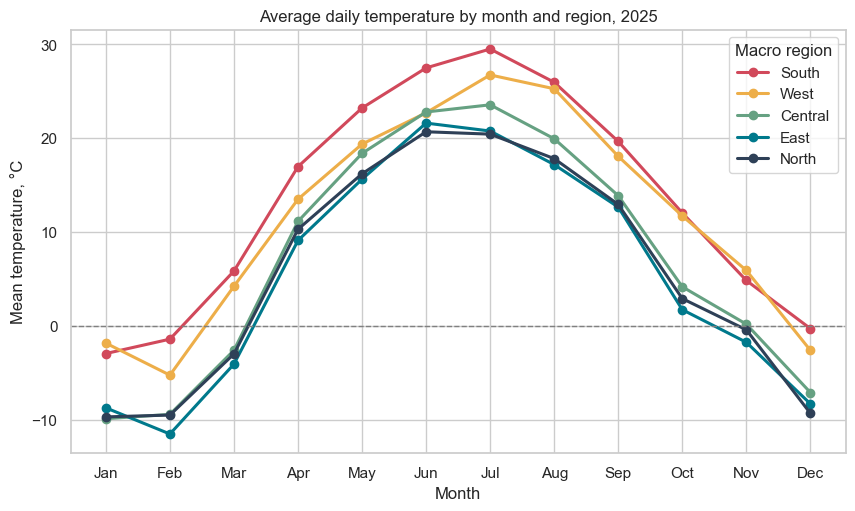

month,1,2,3,4,5,6,7,8,9,10,11,12
macro_region,,,,,,,,,,,,
Central,-9.9,-9.4,-2.6,11.1,18.4,22.8,23.6,19.9,13.9,4.2,0.2,-7.1
East,-8.7,-11.5,-4.1,9.1,15.6,21.6,20.8,17.2,12.7,1.7,-1.8,-8.3
North,-9.7,-9.5,-3.0,10.3,16.2,20.7,20.4,17.8,12.9,2.9,-0.4,-9.3
South,-3.0,-1.4,5.8,17.0,23.2,27.5,29.5,26.0,19.7,12.0,4.8,-0.3
West,-1.8,-5.3,4.2,13.5,19.4,22.7,26.7,25.3,18.1,11.7,5.9,-2.6


In [29]:
monthly_region = daily.pivot_table(index='month', columns='macro_region', values='temp_mean', aggfunc='mean')

fig, ax = plt.subplots(figsize=(10, 5.5))
for region in REGION_ORDER:
    ax.plot(monthly_region.index, monthly_region[region], marker='o', lw=2.2,
            color=REGION_COLORS[region], label=region)
ax.axhline(0, color='grey', lw=1, ls='--')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_title('Average daily temperature by month and region, 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Mean temperature, °C')
ax.legend(title='Macro region')
save(fig, '01_monthly_temperature_by_region.png')
plt.show()
monthly_region.round(1).T

**What I see:** all regions have the same shape (cold winter, hot summer), but the South line is higher all year. In January the South and West are about -2...-3 °C, while North, Central and East are about -9...-10 °C. In July the South is about 9 °C warmer than the North. In the North the temperature is below 0 for about 5 months.

### Plot 2. Latitude vs average year temperature (regression)

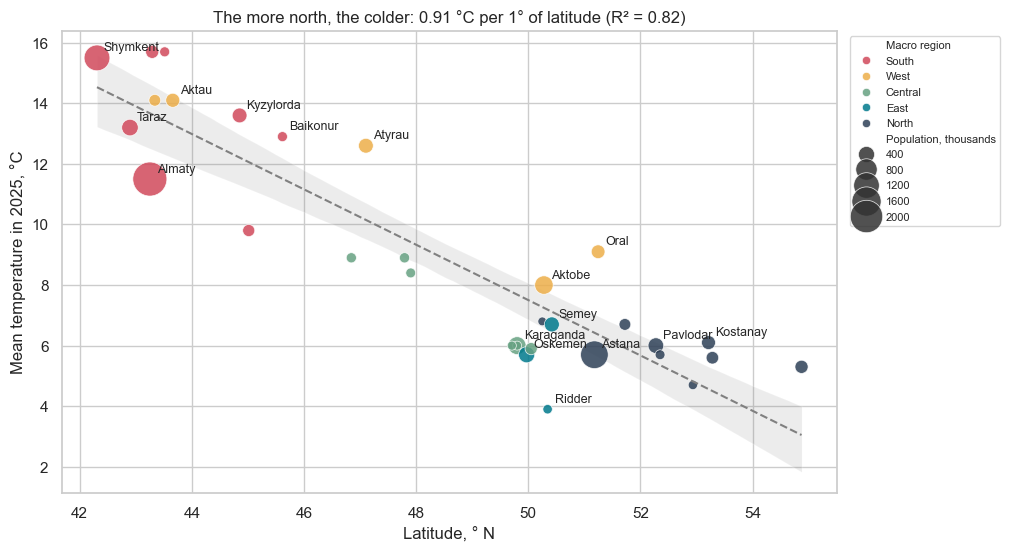

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=cities, x='latitude', y='temp_year', scatter=False, ax=ax,
            color='grey', line_kws={'ls': '--', 'lw': 1.5})
plot_df = cities.assign(population_k=cities['pop_2023'].astype(float) / 1000)  # bubble size = population
sns.scatterplot(data=plot_df, x='latitude', y='temp_year', hue='macro_region', hue_order=REGION_ORDER,
                palette=REGION_COLORS, size='population_k', sizes=(40, 600), alpha=0.85, ax=ax, legend='brief')
for _, row in cities.iterrows():
    if row['pop_2023'] > 250_000 or row['city'] in ('Ridder', 'Baikonur'):
        ax.annotate(row['city'], (row['latitude'], row['temp_year']), xytext=(5, 5),
                    textcoords='offset points', fontsize=9)
ax.set_title(f'The more north, the colder: {abs(slope):.2f} °C per 1° of latitude (R² = {r_lat**2:.2f})')
ax.set_xlabel('Latitude, ° N')
ax.set_ylabel('Mean temperature in 2025, °C')
leg = ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
for t in leg.get_texts():  # nicer legend titles
    t.set_text({'macro_region': 'Macro region', 'population_k': 'Population, thousands'}.get(t.get_text(), t.get_text()))
save(fig, '02_latitude_vs_temperature.png')
plt.show()

**What I see:** a very strong negative link. Latitude alone explains about 80% of the difference in year temperature between cities. Points under the line are mountain or central cities (Ridder in the Altai mountains is the coldest city, Almaty is at the foot of the mountains, 783 m). Points over the line are western cities (Oral, Atyrau, Aktau): they are on low land, and Atyrau and Aktau are on the Caspian Sea, so their winter is softer.

### Plot 3. Frost days and hot days in every city

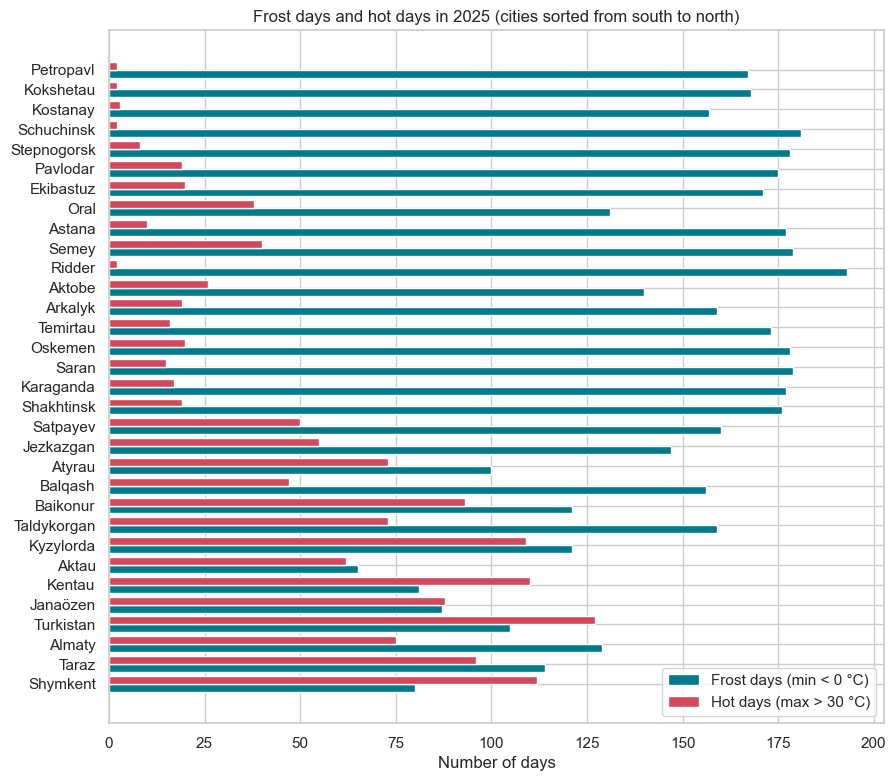

In [31]:
order = cities.sort_values('latitude')['city']
days = cities.set_index('city').loc[order, ['frost_days', 'hot_days']]

fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(days))
ax.barh(y - 0.2, days['frost_days'], height=0.4, color='#00798c', label='Frost days (min < 0 °C)')
ax.barh(y + 0.2, days['hot_days'], height=0.4, color='#d1495b', label='Hot days (max > 30 °C)')
ax.set_yticks(y)
ax.set_yticklabels(days.index)
ax.set_title('Frost days and hot days in 2025 (cities sorted from south to north)')
ax.set_xlabel('Number of days')
ax.legend(loc='lower right')
save(fig, '03_frost_and_hot_days.png')
plt.show()

**What I see:** in the north almost half of the year has frost (150-190 days) and there are almost no hot days. In the south (Turkistan, Shymkent, Kentau, Kyzylorda) there are more than 100 hot days and fewer frost days. Aktau is special: it has the smallest number of frost days because of the Caspian Sea.

### Plot 4. Population history of the biggest cities (melt)
The population columns are in "wide" format (one column per year). For a line plot I need "long" format, so I use `melt`.

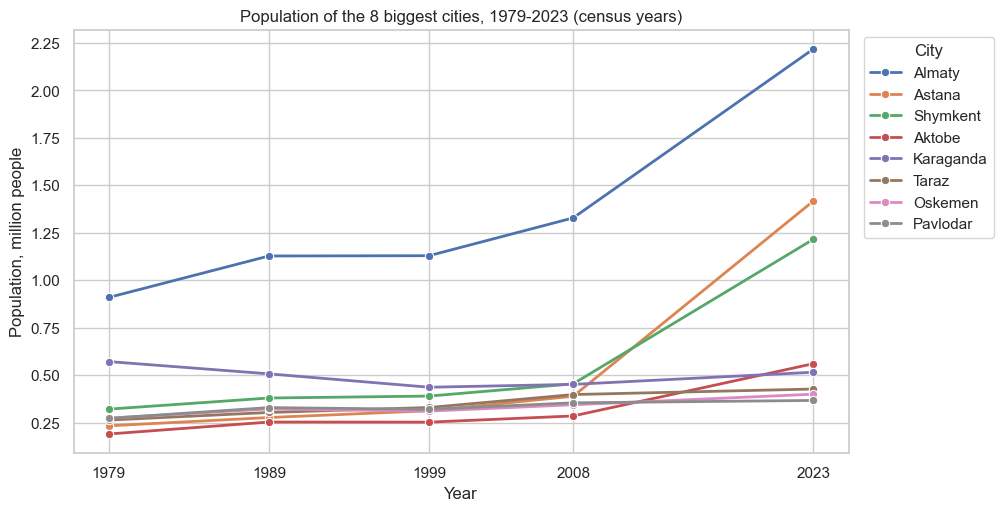

In [32]:
top8 = cities.nlargest(8, 'pop_2023')
pop_long = top8.melt(id_vars='city', value_vars=pop_cols, var_name='year', value_name='population')
pop_long['year'] = pop_long['year'].str[-4:].astype(int)
pop_long['population'] = pop_long['population'].astype(float) / 1e6

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.lineplot(data=pop_long, x='year', y='population', hue='city', marker='o', lw=2, ax=ax)
ax.set_title('Population of the 8 biggest cities, 1979-2023 (census years)')
ax.set_xlabel('Year')
ax.set_ylabel('Population, million people')
ax.set_xticks(sorted(pop_long['year'].unique()))
ax.legend(title='City', bbox_to_anchor=(1.01, 1), loc='upper left')
save(fig, '04_population_history_top8.png')
plt.show()

**What I see:** from 1989 to 1999 most cities did not grow or even lost people (the time after the USSR). After 2008 three cities grow very fast: Almaty, Astana (capital since 1997) and Shymkent (city of republican significance since 2018). Karaganda had more people in 1979 than in 2023.

### Plot 5. Climate vs population growth

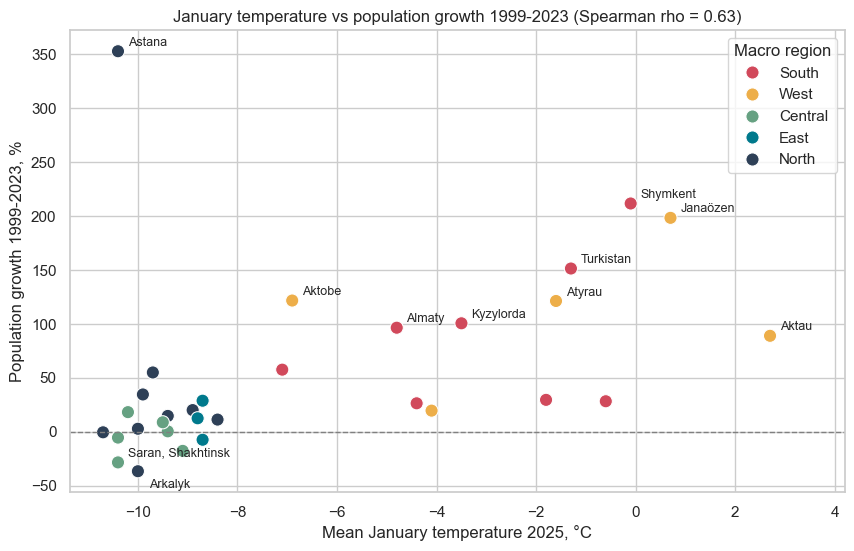

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=cities, x='temp_jan', y='growth_pct', hue='macro_region', hue_order=REGION_ORDER,
                palette=REGION_COLORS, s=90, ax=ax)
ax.axhline(0, color='grey', lw=1, ls='--')
# Saran and Shakhtinsk have almost the same point, so one label for both
label_text = {'Saran': 'Saran, Shakhtinsk', 'Shakhtinsk': None}
label_shift = {'Arkalyk': (8, -12)}
for _, row in cities.iterrows():
    text = label_text.get(row['city'], row['city'])
    if text and (abs(row['growth_pct']) > 60 or row['growth_pct'] < -20):
        ax.annotate(text, (row['temp_jan'], row['growth_pct']), xytext=label_shift.get(row['city'], (7, 4)),
                    textcoords='offset points', fontsize=9)
ax.set_xlim(right=cities['temp_jan'].max() + 1.5)
rho = corr_table.set_index(['x', 'y']).loc[('temp_jan', 'growth_pct'), 'spearman_rho']
ax.set_title(f'January temperature vs population growth 1999-2023 (Spearman rho = {rho})')
ax.set_xlabel('Mean January temperature 2025, °C')
ax.set_ylabel('Population growth 1999-2023, %')
ax.legend(title='Macro region')
save(fig, '05_climate_vs_growth.png')
plt.show()

**What I see:** cities with a warm winter grew more (South and West). All cities that lost people are in the cold group on the left. But Astana is a big exception: very cold winter and the biggest growth (+353%), because it became the capital. So the link is real in the data, but climate is not the only reason (see conclusions).

### Plot 6. Correlation heatmap

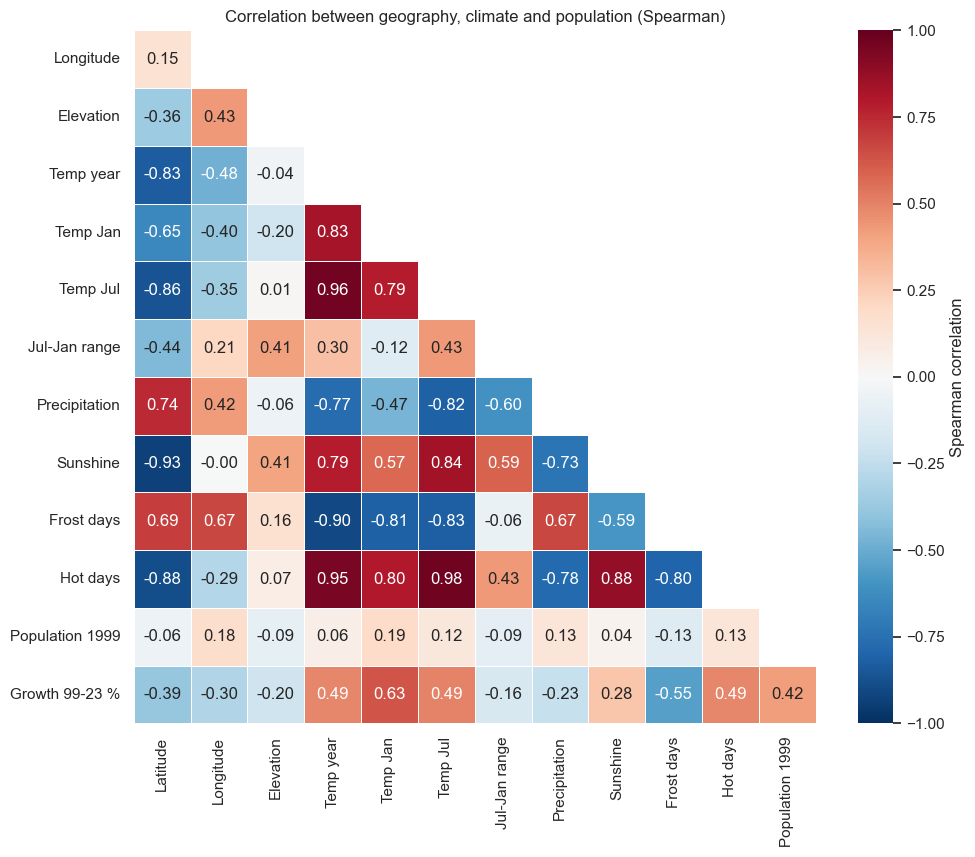

In [34]:
heat_cols = {'latitude': 'Latitude', 'longitude': 'Longitude', 'elevation': 'Elevation',
             'temp_year': 'Temp year', 'temp_jan': 'Temp Jan', 'temp_jul': 'Temp Jul',
             'temp_range': 'Jul-Jan range', 'precip_year_mm': 'Precipitation', 'sunshine_year_h': 'Sunshine',
             'frost_days': 'Frost days', 'hot_days': 'Hot days', 'pop_1999': 'Population 1999',
             'growth_pct': 'Growth 99-23 %'}
corr = cities[list(heat_cols)].astype(float).rename(columns=heat_cols).corr(method='spearman')
corr_low = corr.iloc[1:, :-1]  # lower triangle without the empty first row / last column

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_low, dtype=bool), k=1)
sns.heatmap(corr_low, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.grid(False)
ax.set_title('Correlation between geography, climate and population (Spearman)')
save(fig, '06_correlation_heatmap.png')
plt.show()

**What I see:** the strongest links are between latitude and climate (year temperature, July temperature, hot days, sunshine). Elevation has almost no link with year temperature, because the high cities (Almaty, Taraz, Shymkent) are also in the south, so the effect of height is hidden by latitude. Growth has a positive link with warm winter (0.63) and with the size of the city in 1999 (big cities grew faster).

## 8. Conclusions

**Q1. How does climate change from south to north?**
- Latitude is the main factor of climate: Pearson r = -0.90 between latitude and year temperature. Every 1° to the north the year is about **0.9 °C colder** (R² = 0.82).
- South cities had on average **13.5 °C** in 2025, North cities only **5.8 °C**. In January the South is about -3 °C, the North and Central about -10 °C.
- The North has about 170 frost days and 9 hot days per year, the South about 114 frost days and 99 hot days.

**Q2. Which cities have the most extreme climate?**
- Hottest summer: **Turkistan** (July mean 31.6 °C, max 43.1 °C), then Kentau and Shymkent.
- Coldest winter: **Schuchinsk**, Astana and Saran (January mean about -10.5 °C, Saran had -33.5 °C).
- Most continental (biggest July - January difference): **Balqash, 36.1 °C**, and other Central cities far from the sea.
- Mildest: **Aktau** on the Caspian Sea (only 65 frost days).

**Q3. Is climate connected with population growth?**
- Yes, statistically: Spearman rho = **0.63** (p < 0.001) between January temperature and growth 1999-2023. West (median +121%) and South (+77%) grew, Central cities lost people (median -5.5%).
- All 7 cities that lost population are cold northern / central / eastern towns, most of them are old mining / industrial towns (Arkalyk -37%, Saran -29%, Shakhtinsk -29%, Jezkazgan -18%).
- **But correlation is not causation.** Astana is very cold and grew the most (+353%) because it is the capital. Western cities grow because of oil (Atyrau, Aktau, Janaözen). The South has a high birth rate. So climate is one factor that is mixed with economy and politics.

**Limitations**
- Weather is only for one year (2025), not a 30-year climate norm.
- Open-Meteo data is a model on a grid (reanalysis), not a city weather station. For mountain places it can be less exact (for example, very high rain for Ridder).
- Only 32 cities from one Wikipedia table; Wikipedia numbers can have mistakes and 2023 is an estimate.
- Coordinates are one point for the whole city.

**Possible next steps:** take 10-30 years of weather, add economy data (for example the World Bank or stat.gov.kz API) and build a regression with several factors.

## 9. Output files

In [35]:
for path in sorted(list(RAW.glob('*')) + list(CLEAN.glob('*')) + list(FIG.glob('*'))):
    print(f'{str(path):55s} {path.stat().st_size / 1024:8.1f} KB')

data\processed\cities_climate_population.csv                 6.3 KB
data\processed\weather_daily_2025_clean.csv                884.8 KB
data\processed\wiki_cities_clean.csv                         2.8 KB
data\raw\geocoding_raw.csv                                   1.7 KB
data\raw\weather_daily_2025_raw.csv                        644.1 KB
data\raw\wiki_cities_raw.csv                                 4.5 KB
data\raw\wikipedia_cities_kz.html                          272.4 KB
figures\01_monthly_temperature_by_region.png               156.5 KB
figures\02_latitude_vs_temperature.png                     135.0 KB
figures\03_frost_and_hot_days.png                          122.9 KB
figures\04_population_history_top8.png                     117.6 KB
figures\05_climate_vs_growth.png                           107.4 KB
figures\06_correlation_heatmap.png                         212.0 KB
